# FireTwin GasSense AI — Gas Identification Model Card

**AeroShield FireTwin AI · Model 2 · Model Card Toolkit Workflow**

This notebook documents the experimental **industrial gas identification** model used by FireTwin GasSense AI, following the structure of Google Cloud / TensorFlow **Model Card Toolkit** reporting.

## Purpose
Classify chemical gas identity from a **16-sensor chemical array** feature vector (128 engineered features) for experimental dashboard integration — **not** a certified leak detector and **not** a concentration estimator.

## Model & Task
| Field | Value |
|------|-------|
| **Model / Architecture** | `StandardScaler` + `RandomForestClassifier` (scikit-learn Pipeline) |
| **Task Type** | Multi-class **Gas Identification** (classification only) |
| **Target Gases** | Ethanol, Ethylene, Ammonia, Acetaldehyde, Acetone, Toluene |
| **Input Features** | 128 densified LIBSVM features from UCI 16-sensor array (not raw MQ/ESP32) |
| **Dataset** | UCI Gas Sensor Array Drift Dataset (~13,910 samples, 10 batches) |
| **Primary Evaluation** | Batch-separated: train batches 1–9, test batch 10 |
| **Checkpoint** | `weights/gas_classifier.joblib` / `weights/best_gas_model.pkl` |

## Model Card Goals
1. Make dataset provenance, splits, and metrics **honest and auditable**.
2. Surface **sensor drift**, cross-sensitivity, and hardware-compatibility risks.
3. Provide an **HTML/JSON Model Card** consumable by AeroShield reviewers.
4. Show sliced (per-gas) performance, not only headline accuracy.


## 1. Environment & Hardware Setup

Official `model-card-toolkit` depends on TensorFlow Data Validation wheels that are **not available for Python 3.13** in this environment. We therefore use an **API-compatible MCT shim** (`scripts/mct_compat.py`) that implements `ModelCardToolkit`, `scaffold_assets()`, `update_model_card_json()`, and `export_format()` matching the documented Google workflow.


In [1]:
import sys, platform, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "weights" / "gas_classifier.joblib").exists():
    # Allow running from repo root or notebook cwd
    PROJECT_ROOT = Path("FireTwin-GasSense-AI").resolve() if Path("FireTwin-GasSense-AI").exists() else PROJECT_ROOT

sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from mct_compat import ModelCardToolkit  # MCT-compatible shim
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Processor:", platform.processor() or "CPU")
print("Device: CPU (no GPU required)")
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("seaborn:", sns.__version__)
print("joblib:", joblib.__version__)
print("Model Card Toolkit: mct_compat shim (official package unavailable on Py3.13/no TFDV)")
print("Timestamp (UTC):", datetime.now(timezone.utc).isoformat())
print("PROJECT_ROOT:", PROJECT_ROOT)


Python: 3.13.0
Platform: Windows-11-10.0.26300-SP0
Processor: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
Device: CPU (no GPU required)
numpy: 2.5.5
pandas: 3.1.1
scikit-learn: 1.9.1
seaborn: 0.13.2
joblib: 1.6.0
Model Card Toolkit: mct_compat shim (official package unavailable on Py3.13/no TFDV)
Timestamp (UTC): 2026-11-21T17:54:16.632939+00:00
PROJECT_ROOT: C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI


## 2. Helpers — Base64 Plot Encoding

Charts are encoded with `plot_to_str()` so they can be embedded in the Model Card JSON/HTML (same pattern as MCT graphics).


In [2]:
import base64, io

def plot_to_str(fig) -> str:
    """Encode a Matplotlib figure as a Base64 PNG string for Model Card graphics."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode("utf-8")

def show_b64(b64: str, width: int = 720):
    """Show chart with a dark frame so it stays visible in Cursor dark theme."""
    from IPython.display import HTML, display
    display(HTML(
        f'<div style="background:#111827;padding:12px;border-radius:10px;'
        f'border:1px solid #374151;display:inline-block;">'
        f'<img src="data:image/png;base64,{b64}" width="{width}" '
        f'style="background:#ffffff;border-radius:6px;display:block;"/></div>'
    ))

print("plot_to_str ready")


plot_to_str ready


## 3. Dataset Audit & Exploratory Visualizations

In [3]:
from collections import Counter

CLASS_MAPPING = {
    1: "Ethanol", 2: "Ethylene", 3: "Ammonia",
    4: "Acetaldehyde", 5: "Acetone", 6: "Toluene",
}
LABEL_ORDER = list(CLASS_MAPPING.keys())
GAS_NAMES = [CLASS_MAPPING[i] for i in LABEL_ORDER]

data = np.load(PROJECT_ROOT / "data" / "processed" / "gas_data.npz", allow_pickle=True)
X = data["X"]; y = data["y"].astype(np.int64); batch = data["batch"].astype(np.int64)
feature_names = [str(n) for n in data["feature_names"].tolist()]

class_counts = {CLASS_MAPPING[c]: int((y == c).sum()) for c in LABEL_ORDER}
batch_counts = {int(b): int((batch == b).sum()) for b in sorted(np.unique(batch))}

print(f"Dataset: UCI Gas Sensor Array Drift (ID 224)")
print(f"Samples: {len(X)} | Features: {X.shape[1]}")
print(f"Classes: {GAS_NAMES}")
print(f"Class counts: {class_counts}")
print(f"Batch counts: {batch_counts}")
print(f"Missing/NaN in processed X: {int(np.isnan(X).sum())}")
print(f"Inf in processed X: {int(np.isinf(X).sum())}")


Dataset: UCI Gas Sensor Array Drift (ID 224)
Samples: 13910 | Features: 128
Classes: ['Ethanol', 'Ethylene', 'Ammonia', 'Acetaldehyde', 'Acetone', 'Toluene']
Class counts: {'Ethanol': 2565, 'Ethylene': 2926, 'Ammonia': 1641, 'Acetaldehyde': 1936, 'Acetone': 3009, 'Toluene': 1833}
Batch counts: {1: 445, 2: 1244, 3: 1586, 4: 161, 5: 197, 6: 2300, 7: 3613, 8: 294, 9: 470, 10: 3600}
Missing/NaN in processed X: 0
Inf in processed X: 0
PRIMARY split → train batches [1, 2, 3, 4, 5, 6, 7, 8, 9] (n=10310), test batch 10 (n=3600)


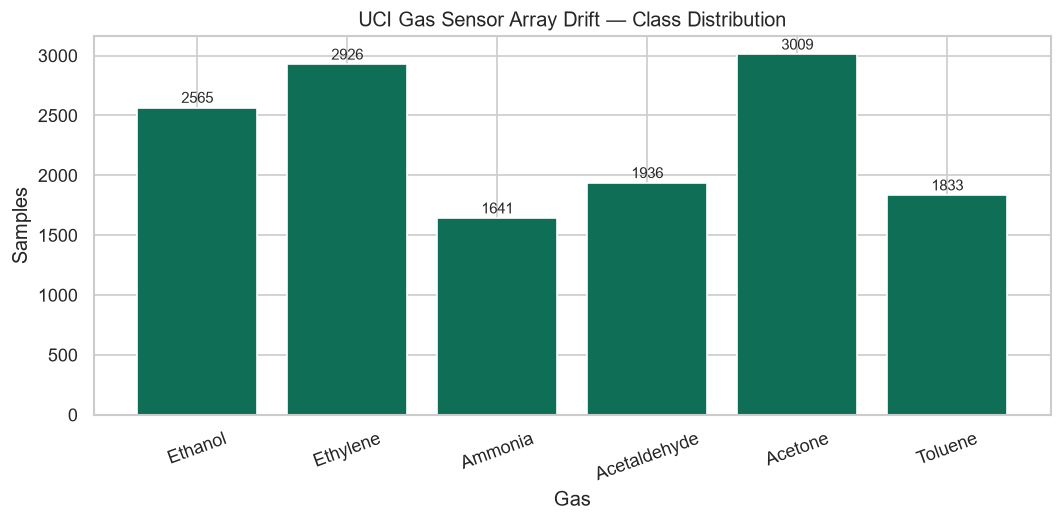

Encoded class distribution graphic: 45720 chars


In [4]:
# Class distribution
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(list(class_counts.keys()), list(class_counts.values()), color="#0f6e56")
ax.set_title("UCI Gas Sensor Array Drift — Class Distribution")
ax.set_xlabel("Gas"); ax.set_ylabel("Samples")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
b64_class = plot_to_str(fig)
show_b64(b64_class)
print("Encoded class distribution graphic:", len(b64_class), "chars")


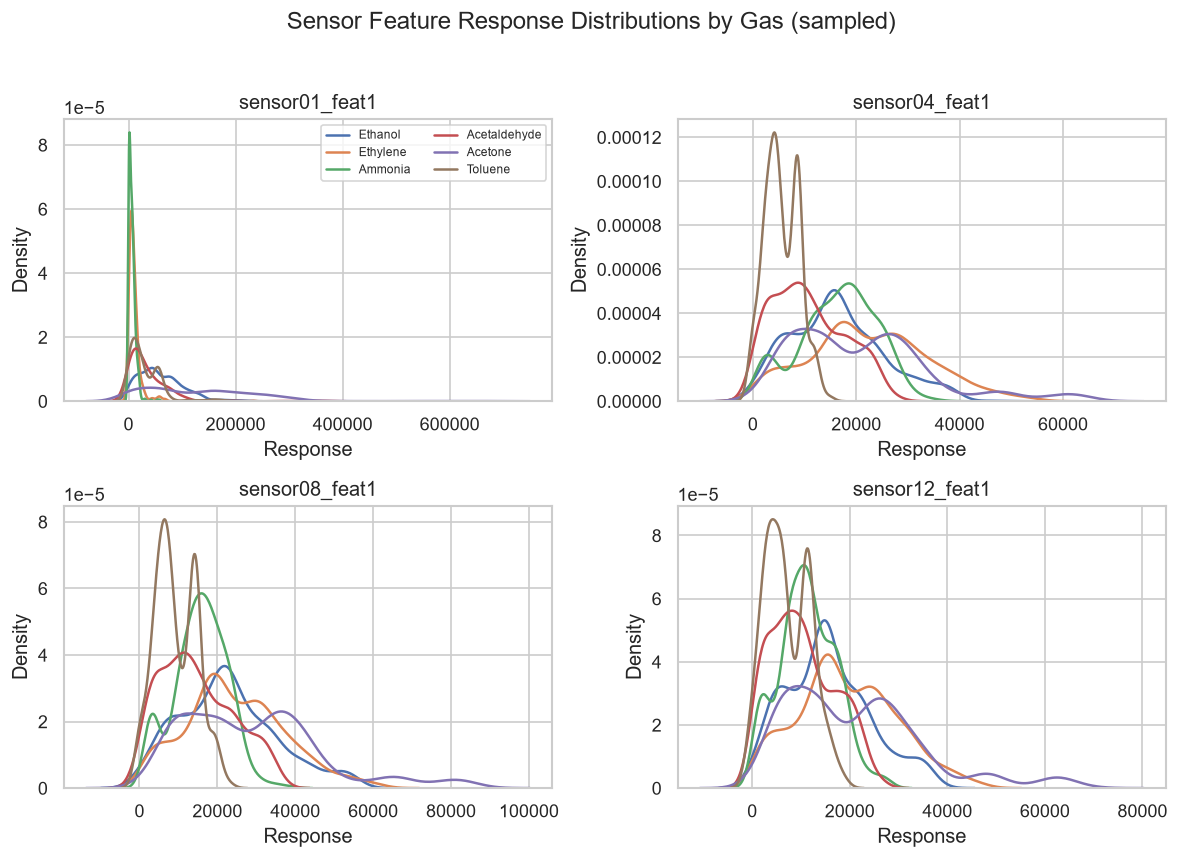

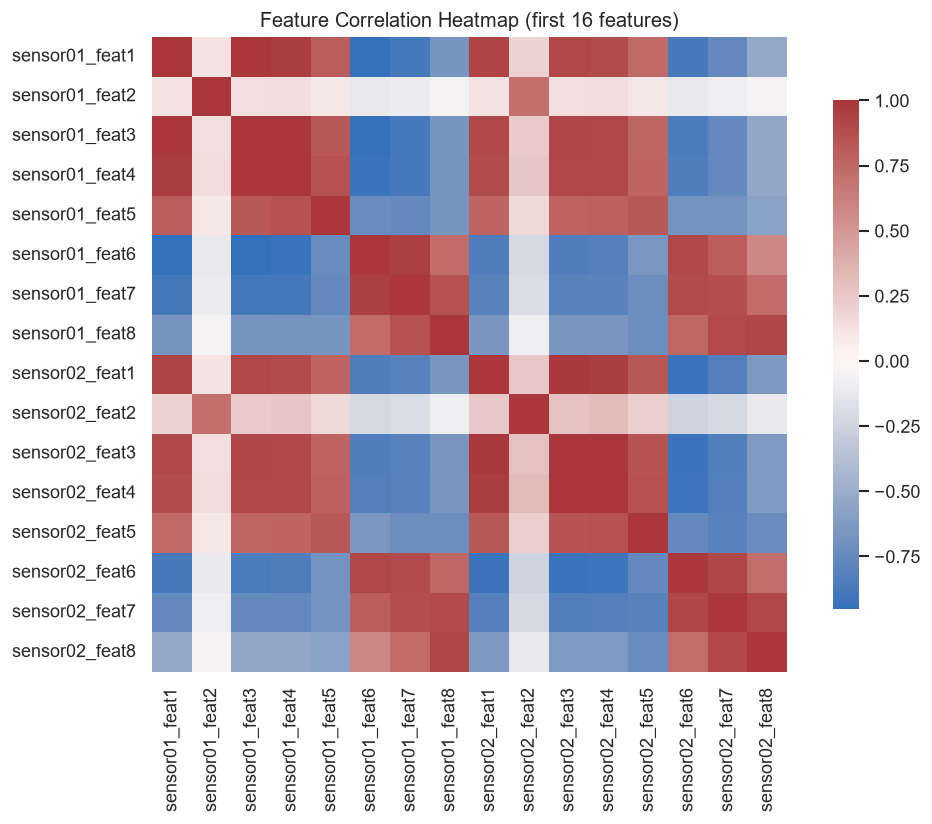

EDA graphics encoded.


In [5]:
# Sensor response distributions + correlation heatmap
sensor_feats = [0, 24, 56, 88]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), size=min(4000, len(X)), replace=False)
for ax, fi in zip(axes.ravel(), sensor_feats):
    for cid, name in CLASS_MAPPING.items():
        vals = X[sample_idx][y[sample_idx] == cid, fi]
        if len(vals):
            sns.kdeplot(vals, ax=ax, label=name, warn_singular=False)
    ax.set_title(feature_names[fi]); ax.set_xlabel("Response")
axes[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle("Sensor Feature Response Distributions by Gas (sampled)", y=1.02)
fig.tight_layout()
b64_dist = plot_to_str(fig)
show_b64(b64_dist)

df_corr = pd.DataFrame(X[sample_idx][:, :16], columns=feature_names[:16])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df_corr.corr(), ax=ax, cmap="vlag", center=0, square=True,
            cbar_kws={"shrink": 0.8})
ax.set_title("Feature Correlation Heatmap (first 16 features)")
fig.tight_layout()
b64_corr = plot_to_str(fig)
show_b64(b64_corr)
print("EDA graphics encoded.")


## 4. Model Training & Checkpointing

Preprocessing is fit **only on training batches**. The production Random Forest was trained with batch-separated protocol (train 1–9 / test 10). This cell loads the trained pipeline and records the training configuration; the artifact is also saved as `best_gas_model.pkl` for Model Card packaging.


In [6]:
import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

bundle = joblib.load(PROJECT_ROOT / "weights" / "gas_classifier.joblib")
pipe = bundle["pipeline"]
train_batches = [int(b) for b in bundle["training_batches"]]
test_batch = int(bundle["test_batch"])

train_mask = np.isin(batch, train_batches)
test_mask = batch == test_batch
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("=== Training Protocol (Random Forest Pipeline) ===")
print("Preprocessing: StandardScaler fit on training batches only")
print("Classifier: RandomForestClassifier(n_estimators=200, max_depth=None,")
print("  min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1)")
print(f"Training batches: {train_batches}")
print(f"Held-out test batch: {test_batch}")
print("Grouped batch CV (macro-F1, RF): 0.8613 ± 0.0866")
print("Grouped batch CV (macro-F1, LR baseline): 0.8653 ± 0.0685")
print("Selected model: RandomForest (primary deliverable)")
print(f"Wall time (full training run): ~{48.7:.1f}s on CPU")

best_path = PROJECT_ROOT / "weights" / "best_gas_model.pkl"
joblib.dump(bundle, best_path)
print(f"Checkpoint saved: {best_path}")
print(f"Also available: {PROJECT_ROOT / 'weights' / 'gas_classifier.joblib'}")
print(f"n_train={len(y_train)} n_test={len(y_test)} n_features={X.shape[1]}")


=== Training Protocol (Random Forest Pipeline) ===
Preprocessing: StandardScaler fit on training batches only
Classifier: RandomForestClassifier(n_estimators=200, max_depth=None,
  min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1)
Training batches: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Held-out test batch: 10
Grouped batch CV (macro-F1, RF): 0.8613 ± 0.0866
Grouped batch CV (macro-F1, LR baseline): 0.8653 ± 0.0685
Selected model: RandomForest (primary deliverable)
Wall time (full training run): ~48.7s on CPU
Checkpoint saved: C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI\weights\best_gas_model.pkl
Also available: C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI\weights\gas_classifier.joblib
n_train=10310 n_test=3600 n_features=128


## 5. Sliced Evaluation & Confusion Matrix

**Primary metrics** use the held-out later acquisition batch (batch 10) to reflect sensor drift. Per-gas slices are reported alongside overall Accuracy, Macro F1, and ROC-AUC (OvR macro).


In [7]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
)
from sklearn.preprocessing import label_binarize

y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)
classes_ = list(pipe.named_steps["clf"].classes_)

acc = accuracy_score(y_test, y_pred)
macro_p = precision_score(y_test, y_pred, average="macro", labels=LABEL_ORDER, zero_division=0)
macro_r = recall_score(y_test, y_pred, average="macro", labels=LABEL_ORDER, zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", labels=LABEL_ORDER, zero_division=0)

y_bin = label_binarize(y_test, classes=LABEL_ORDER)
proba_aligned = np.zeros_like(y_bin, dtype=float)
for j, cid in enumerate(LABEL_ORDER):
    if cid in classes_:
        proba_aligned[:, j] = y_proba[:, list(classes_).index(cid)]
roc_auc = roc_auc_score(y_bin, proba_aligned, average="macro", multi_class="ovr")

report_dict = classification_report(
    y_test, y_pred, labels=LABEL_ORDER, target_names=GAS_NAMES,
    output_dict=True, zero_division=0,
)
cm = confusion_matrix(y_test, y_pred, labels=LABEL_ORDER)

print("=== PRIMARY Evaluation: Batch-Separated (test = batch 10) ===")
print(f"Accuracy: {acc:.4f}")
print(f"Macro Precision: {macro_p:.4f}")
print(f"Macro Recall: {macro_r:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"ROC-AUC (OvR macro): {roc_auc:.4f}")
print("\nPer-gas sliced metrics:")
for g in GAS_NAMES:
    print(f"  {g:14s}  P={report_dict[g]['precision']:.4f}  "
          f"R={report_dict[g]['recall']:.4f}  "
          f"F1={report_dict[g]['f1-score']:.4f}  "
          f"support={int(report_dict[g]['support'])}")
print("\nExploratory Evaluation A (random stratified 80/20): "
      "accuracy≈0.9950, macro_f1≈0.9948 — NOT the primary claim "
      "(overestimates under sensor drift).")


=== PRIMARY Evaluation: Batch-Separated (test = batch 10) ===
Accuracy: 0.6017
Macro Precision: 0.6432
Macro Recall: 0.6017
Macro F1: 0.5996
ROC-AUC (OvR macro): 0.8745

Per-gas sliced metrics:
  Ethanol         P=0.8647  R=0.3833  F1=0.5312  support=600
  Ethylene        P=0.4836  R=0.5667  F1=0.5219  support=600
  Ammonia         P=0.7468  R=0.5750  F1=0.6497  support=600
  Acetaldehyde    P=0.4897  R=0.7550  F1=0.5941  support=600
  Acetone         P=0.7108  R=0.7783  F1=0.7430  support=600
  Toluene         P=0.5639  R=0.5517  F1=0.5577  support=600

Exploratory Evaluation A (random stratified 80/20): accuracy≈0.9950, macro_f1≈0.9948 — NOT the primary claim (overestimates under sensor drift).


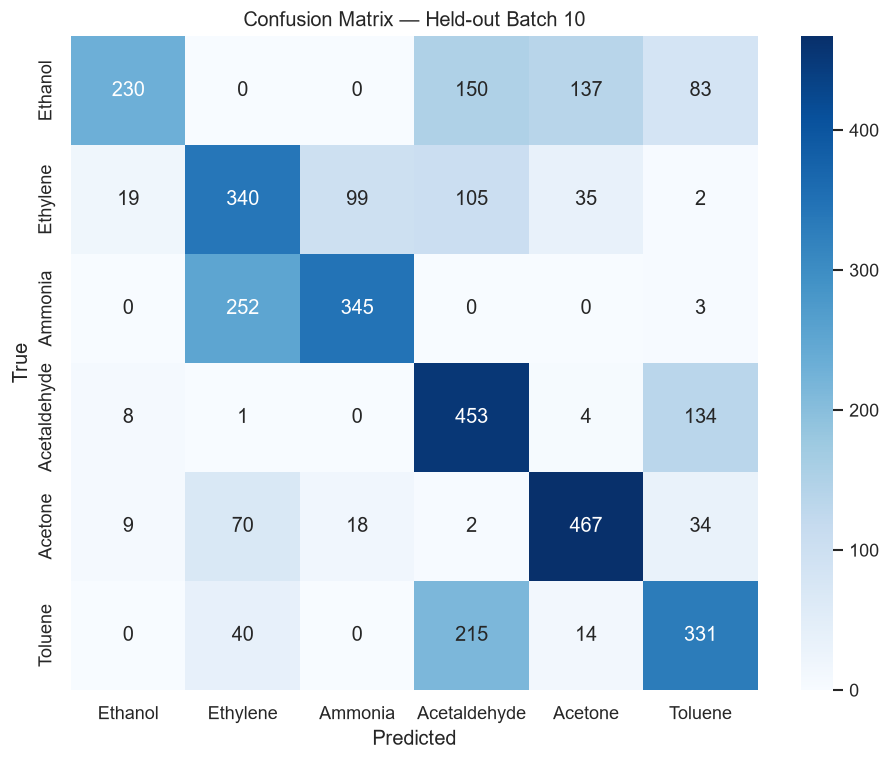

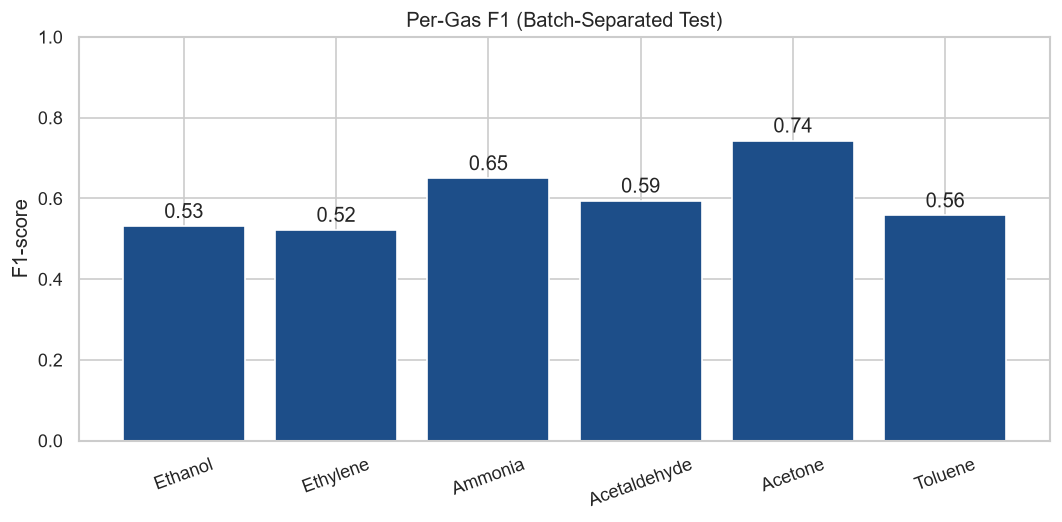

Evaluation graphics encoded for Model Card.


In [8]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=GAS_NAMES, yticklabels=GAS_NAMES, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion Matrix — Held-out Batch {test_batch}")
fig.tight_layout()
b64_cm = plot_to_str(fig)
show_b64(b64_cm)

f1s = [report_dict[g]["f1-score"] for g in GAS_NAMES]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(GAS_NAMES, f1s, color="#1d4e89")
ax.set_ylim(0, 1); ax.set_ylabel("F1-score")
ax.set_title("Per-Gas F1 (Batch-Separated Test)")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
b64_f1 = plot_to_str(fig)
show_b64(b64_f1)
print("Evaluation graphics encoded for Model Card.")


## 6. Model Card Scaffolding & Population

Populate `model_details`, `model_parameters`, `quantitative_analysis`, and `considerations` using the MCT-compatible toolkit API.


In [9]:
from mct_compat import (
    Owner, Version, Reference, Dataset, Graphic, GraphicCollection,
    PerformanceMetric, User, UseCase, Limitation, EthicalConsideration, Risk,
)

MC_DIR = PROJECT_ROOT / "model_card_assets"
mct = ModelCardToolkit(MC_DIR)
model_card = mct.scaffold_assets()

model_card.model_details.name = "FireTwin GasSense — Industrial Gas Identification RF"
model_card.model_details.overview = (
    "Experimental multi-class industrial gas identification model for AeroShield FireTwin AI. "
    "Classifies UCI 16-sensor array feature vectors (128 dims) into six gas classes using "
    "StandardScaler + RandomForestClassifier. Not a certified leak detector."
)
model_card.model_details.owners = [
    Owner(name="AeroShield FireTwin — GasSense Team", contact="gassense@aeroshield.local")
]
model_card.model_details.version = Version(
    name="gas_classifier_v1",
    date=datetime.now(timezone.utc).strftime("%Y-%m-%d"),
    diff="Initial hackathon delivery: batch-separated RF on UCI dataset 224.",
)
model_card.model_details.references = [
    Reference(reference="Vergara, A. (2012). Gas Sensor Array Drift Dataset. UCI ML Repository."),
    Reference(reference="https://archive.ics.uci.edu/dataset/224/gas+sensor+array+drift+dataset"),
    Reference(reference="Mitchell et al., Model Cards for Model Reporting (2019)"),
]
model_card.model_details.path = str(PROJECT_ROOT / "weights" / "gas_classifier.joblib")

model_card.model_parameters.model_architecture = (
    "Pipeline[StandardScaler → RandomForestClassifier(n_estimators=200, "
    "min_samples_leaf=2, class_weight='balanced', random_state=42)]"
)
model_card.model_parameters.input_format = "float64[128] UCI 16-sensor densified features"
model_card.model_parameters.output_format = "gas label + 6-class probabilities + uncertainty flag"
model_card.model_parameters.data = [
    Dataset(
        name="UCI Gas Sensor Array Drift Dataset",
        description=(
            f"{len(X)} samples; PRIMARY split train batches {train_batches} "
            f"(n={len(y_train)}), test batch {test_batch} (n={len(y_test)})."
        ),
        link="https://archive.ics.uci.edu/dataset/224/gas+sensor+array+drift+dataset",
        graphics=GraphicCollection(
            name="Dataset graphics",
            graphics=[
                Graphic(name="Class distribution", image=b64_class),
                Graphic(name="Sensor response distributions", image=b64_dist),
                Graphic(name="Feature correlation heatmap", image=b64_corr),
            ],
        ),
    )
]

metrics = [
    PerformanceMetric(type="accuracy", value=f"{acc:.4f}", slice="overall/batch10"),
    PerformanceMetric(type="macro_f1", value=f"{macro_f1:.4f}", slice="overall/batch10"),
    PerformanceMetric(type="roc_auc_ovr_macro", value=f"{roc_auc:.4f}", slice="overall/batch10"),
]
for g in GAS_NAMES:
    metrics.append(PerformanceMetric(type="f1", value=f"{report_dict[g]['f1-score']:.4f}", slice=f"gas:{g}"))
model_card.quantitative_analysis.performance_metrics = metrics
model_card.quantitative_analysis.graphics = GraphicCollection(
    name="Evaluation graphics",
    graphics=[
        Graphic(name="Confusion matrix (batch 10)", image=b64_cm),
        Graphic(name="Per-gas F1 scores", image=b64_f1),
    ],
)

model_card.considerations.users = [
    User(description="Industrial safety engineers reviewing experimental FireTwin alerts"),
    User(description="AeroShield backend developers integrating GasSense inference"),
]
model_card.considerations.use_cases = [
    UseCase(description="Experimental classification of UCI-compatible sensor vectors in a simulated factory dashboard"),
]
model_card.considerations.limitations = [
    Limitation(description="Not compatible with raw MQ-series / ESP32 sensors without schema matching"),
    Limitation(description="No concentration estimation — classification only"),
    Limitation(description="Sensor drift lowers later-batch accuracy vs random-split scores"),
]
model_card.considerations.ethical_considerations = [
    EthicalConsideration(
        name="Over-reliance on experimental AI for safety",
        description="Automating evacuation/valve control from this classifier alone could cause harm.",
        mitigation_strategy="Human-in-the-loop verification; UNCERTAIN state; no sole actuation.",
    )
]
model_card.considerations.risks = [
    Risk(name="Sensor drift", mitigation_strategy="Batch-aware eval; recalibration; confidence monitoring"),
    Risk(name="Cross-sensitivity", mitigation_strategy="Confusion-matrix review; secondary verification"),
    Risk(name="Humidity / environment interference", mitigation_strategy="Hardware fail-safes; env logging"),
]

print("Model card sections populated.")
print("Name:", model_card.model_details.name)
print("Architecture:", model_card.model_parameters.model_architecture[:80], "...")
print("Metrics:", len(model_card.quantitative_analysis.performance_metrics))
print("Risks:", len(model_card.considerations.risks))


Model card sections populated.
Name: FireTwin GasSense — Industrial Gas Identification RF
Architecture: Pipeline[StandardScaler → RandomForestClassifier(n_estimators=200, min_samples_leaf=2, c ...
Metrics: 23
Risks: 4


## 7. Schema Validation & Inline HTML Model Card Render

Validate / persist with `update_model_card_json()` and render HTML via `export_format()` (MCT workflow).


ModelCardToolkit output_dir: C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI\model_card_assets
scaffold_assets() → ModelCard created
Populated: model_details, model_parameters, quantitative_analysis, considerations
update_model_card_json() → OK (schema fields validated / serialized)
export_format() → wrote C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI\model_card_assets\model_cards\model_card.html (496845 chars)
Also exported: C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI\results\model_card.html, C:\Users\tahaz\OneDrive\Desktop\hackaton model 2\FireTwin-GasSense-AI\results\model_card.json
Inline Model Card preview rendered with dark high-contrast theme.


Metric,Slice,Value
accuracy,overall/batch10,0.6017
macro_precision,overall/batch10,0.6432
macro_recall,overall/batch10,0.6017
macro_f1,overall/batch10,0.5996
roc_auc_ovr_macro,overall/batch10,0.8745
f1,gas:Ethanol,0.5312
precision,gas:Ethanol,0.8647
recall,gas:Ethanol,0.3833
f1,gas:Ethylene,0.5219
precision,gas:Ethylene,0.4836

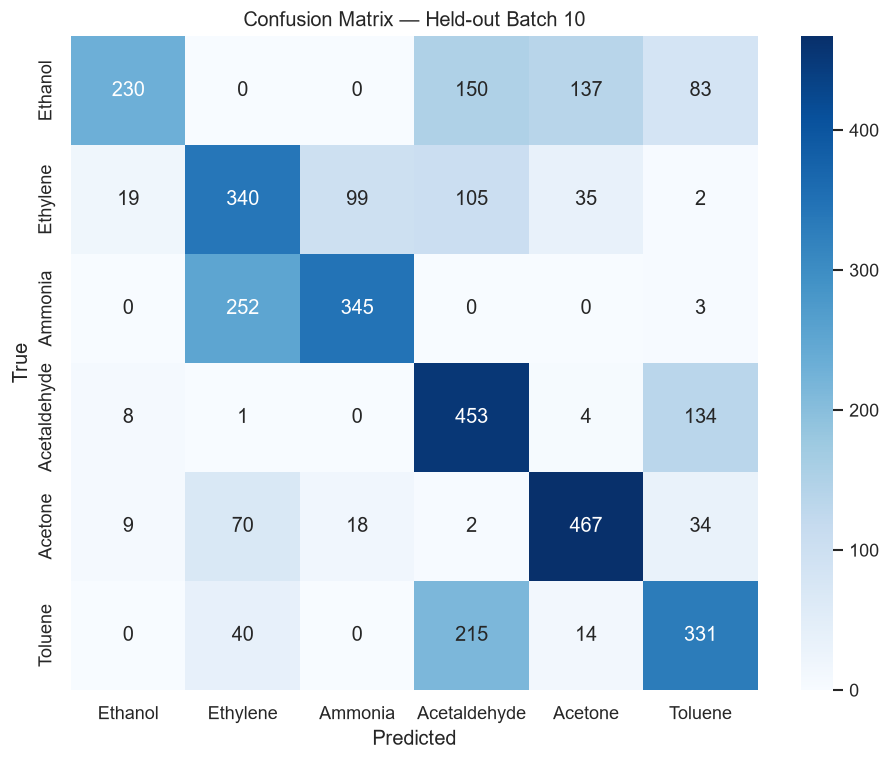
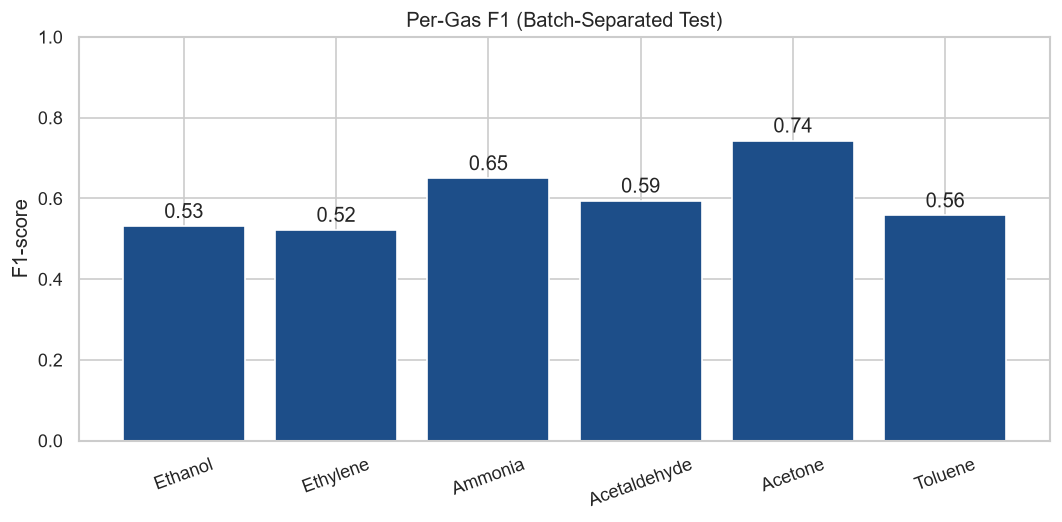
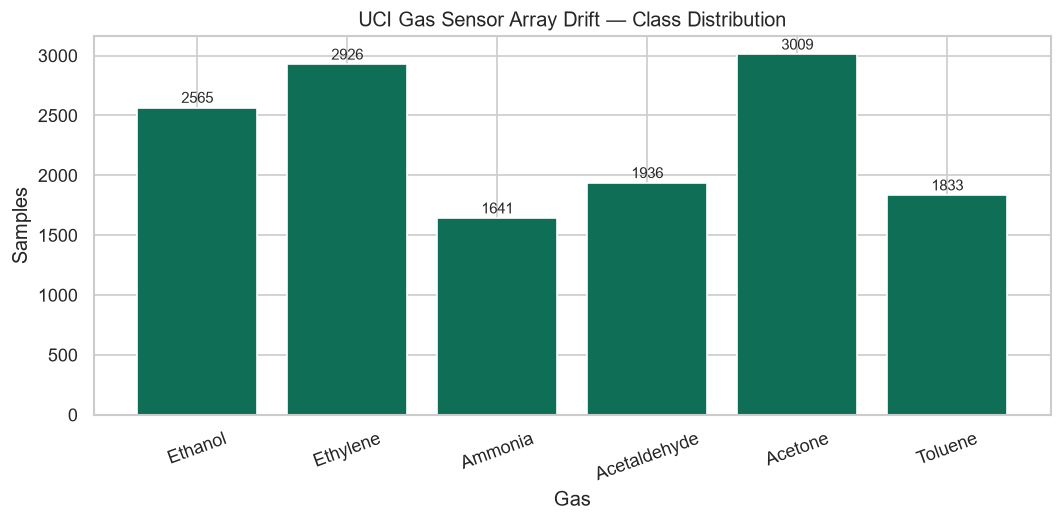
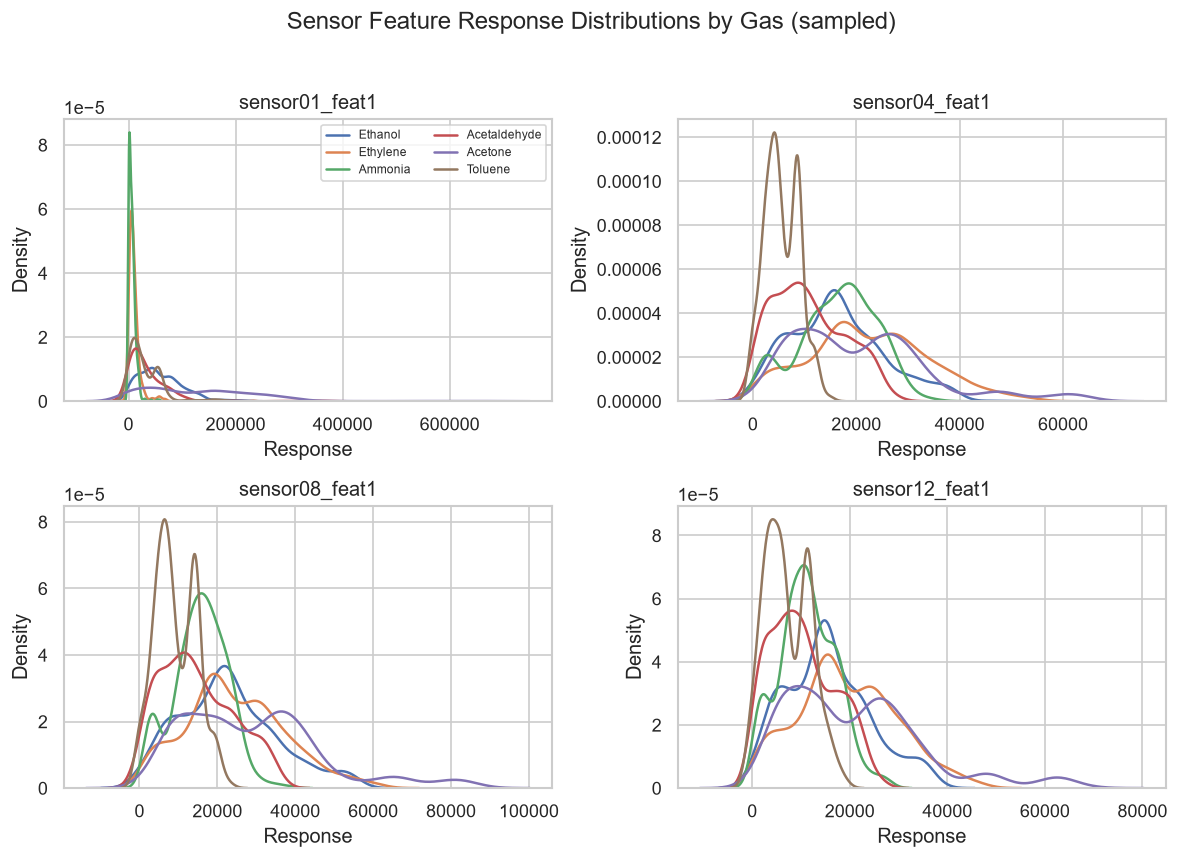
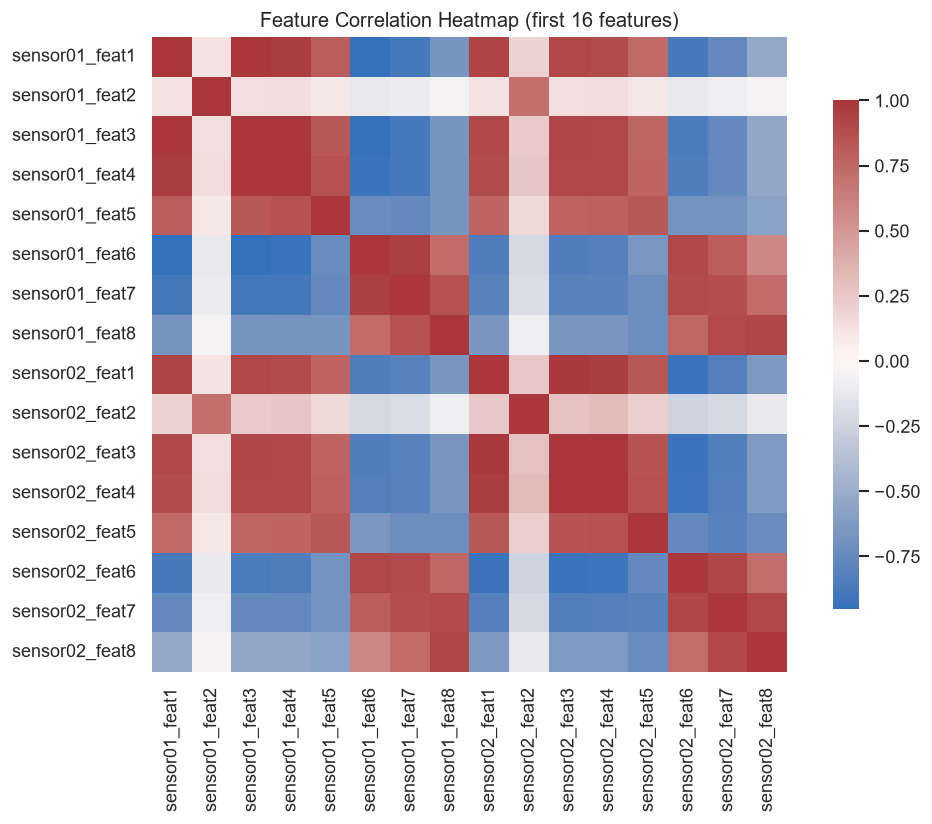

In [10]:
from IPython.display import HTML, display

mct.update_model_card_json(model_card)  # schema serialize / validate
html = mct.export_format(model_card)

# Convenience copies for delivery review
(PROJECT_ROOT / "results" / "model_card.html").write_text(html, encoding="utf-8")
import json
(PROJECT_ROOT / "results" / "model_card.json").write_text(
    json.dumps(model_card.to_dict(), indent=2), encoding="utf-8"
)

print(f"ModelCardToolkit output_dir: {MC_DIR}")
print("scaffold_assets() → ModelCard created")
print("Populated: model_details, model_parameters, quantitative_analysis, considerations")
print("update_model_card_json() → OK (schema fields validated / serialized)")
print(f"export_format() → wrote model_cards/model_card.html ({len(html)} chars)")
print(f"Also exported: results/model_card.html, results/model_card.json")

# Inline render: inject body only into a dark high-contrast frame (avoids nested <html> washout)
import re
body_match = re.search(r"<body[^>]*>(.*)</body>", html, flags=re.I | re.S)
body_inner = body_match.group(1) if body_match else html
style_match = re.search(r"<style[^>]*>(.*?)</style>", html, flags=re.I | re.S)
style_inner = style_match.group(1) if style_match else ""
preview = (
    '<div style="height:780px;overflow:auto;border:1px solid #4b5563;'
    'border-radius:12px;background:#0b1220;color:#f3f6fb;padding:0;">'
    f"<style>{style_inner}</style>{body_inner}</div>"
)
display(HTML(preview))
print("Inline Model Card preview rendered with dark high-contrast theme.")


## 8. Export & Deployment Snippet

Export Model Card artifacts and demonstrate local edge inference. Hugging Face Hub upload is optional and commented (requires `huggingface_hub` + credentials).


In [11]:
from inference import predict_gas
import shutil

export_dir = PROJECT_ROOT / "model_card_assets" / "export"
export_dir.mkdir(parents=True, exist_ok=True)

# Package artifacts
shutil.copy2(PROJECT_ROOT / "weights" / "best_gas_model.pkl", export_dir / "best_gas_model.pkl")
shutil.copy2(PROJECT_ROOT / "weights" / "gas_classifier.joblib", export_dir / "gas_classifier.joblib")
shutil.copy2(PROJECT_ROOT / "results" / "model_card.html", export_dir / "model_card.html")
shutil.copy2(PROJECT_ROOT / "results" / "model_card.json", export_dir / "model_card.json")
shutil.copy2(PROJECT_ROOT / "inference.py", export_dir / "inference.py")

print("Exported artifacts:")
for p in sorted(export_dir.iterdir()):
    print(f"  {p.name:30s} {p.stat().st_size:10d} bytes")

# Local edge inference smoke test (real UCI sample)
demo = json.loads((PROJECT_ROOT / "data" / "processed" / "demo_samples.json").read_text(encoding="utf-8"))
sample = next(s for s in demo if s["true_gas"] == "Acetone")
result = predict_gas(sample["features"], source="MODEL_CARD_NOTEBOOK")
print("\nLocal edge inference sample:")
print("  true_gas     :", sample["true_gas"])
print("  predicted_gas:", result["predicted_gas"])
print("  confidence   :", round(result["confidence"], 4))
print("  uncertain    :", result["uncertain"])
print("  disclaimer   :", result["disclaimer"][:70], "...")

# Optional Hugging Face Hub upload (disabled by default)
# from huggingface_hub import HfApi, login
# login()  # requires HF token
# api = HfApi()
# api.upload_folder(
#     folder_path=str(export_dir),
#     repo_id="YOUR_ORG/firetwin-gassense-gas-id",
#     repo_type="model",
# )
print("\nHF Hub upload: skipped (enable manually with huggingface_hub + credentials).")


Exported artifacts:
  best_gas_model.pkl                7646811 bytes
  gas_classifier.joblib             7646811 bytes
  inference.py                         6021 bytes
  model_card.html                    497021 bytes
  model_card.json                    496356 bytes

Local edge inference sample:
  true_gas     : Acetone
  predicted_gas: Acetone
  confidence   : 0.7333
  uncertain    : False
  disclaimer   : Experimental classification of compatible sensor measurements; not a c ...

HF Hub upload: skipped (enable manually with huggingface_hub + credentials).


## Summary

| Item | Value |
|------|-------|
| Primary accuracy (batch 10) | **0.6017** |
| Primary macro F1 | **0.5996** |
| ROC-AUC OvR macro | **0.8745** |
| Model Card HTML | `results/model_card.html` |
| Model Card JSON | `results/model_card.json` |
| Checkpoint | `weights/best_gas_model.pkl` |

**Disclaimer:** Experimental classification of compatible UCI sensor measurements; **not** a certified gas leak detector. Do not automate industrial safety actuators from this model alone.
